In [27]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import deque
from dataclasses import dataclass
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED        = 42
BOARD_SIZE  = 7
WIN_LEN     = 5
N_ACTIONS   = BOARD_SIZE * BOARD_SIZE
EMPTY, PLAYER_X, PLAYER_O = 0, 1, 2

NUM_EPISODES       = 40_000
BATCH_SIZE         = 128
LR                 = 5e-4
GAMMA              = 0.99
BUFFER_SIZE        = 200_000
TARGET_UPDATE      = 1_000
EPS_START          = 1.0
EPS_END            = 0.05
EPS_DECAY_EPISODES = 15_000
WARMUP             = 3_000
GRAD_STEPS         = 1

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


In [2]:
class TicTacToe5:
    def __init__(self):
        self.reset()

    def reset(self):
        self.board = np.zeros((BOARD_SIZE, BOARD_SIZE), dtype=np.int8)
        self.current_player = PLAYER_X
        self.done = False
        self.winner = 0
        self.move_count = 0
        return self.get_state()

    def legal_moves(self):
        return self.board.flatten() == EMPTY

    def step(self, action):
        assert not self.done
        r, c = divmod(action, BOARD_SIZE)
        assert self.board[r, c] == EMPTY

        self.board[r, c] = self.current_player
        self.move_count += 1

        if self._check_win(r, c, self.current_player):
            self.done = True
            self.winner = self.current_player
            return self.get_state(), +1.0, True, {"winner": self.current_player}

        if self.move_count == BOARD_SIZE * BOARD_SIZE:
            self.done = True
            self.winner = 0
            return self.get_state(), 0.0, True, {"winner": 0}

        self.current_player = 3 - self.current_player
        return self.get_state(), 0.0, False, {}

    def _check_win(self, r, c, player):
        for dr, dc in ((0, 1), (1, 0), (1, 1), (1, -1)):
            cnt = 1
            for sign in (1, -1):
                nr, nc = r + sign * dr, c + sign * dc
                while (0 <= nr < BOARD_SIZE and 0 <= nc < BOARD_SIZE
                       and self.board[nr, nc] == player):
                    cnt += 1
                    nr += sign * dr
                    nc += sign * dc
            if cnt >= WIN_LEN:
                return True
        return False

    def get_state(self):
        me    = (self.board == self.current_player).astype(np.float32)
        opp   = (self.board == (3 - self.current_player)).astype(np.float32)
        empty = (self.board == EMPTY).astype(np.float32)
        return np.stack([me, opp, empty])

    def render(self):
        symbols = {0: ".", 1: "X", 2: "O"}
        print("    " + " ".join(str(i) for i in range(BOARD_SIZE)))
        for r in range(BOARD_SIZE):
            print(f"{r}:  " + " ".join(symbols[self.board[r, c]]
                                       for c in range(BOARD_SIZE)))
        print()

In [3]:
env = TicTacToe5()
env.render()

moves = [0, 7, 1, 8, 2, 9, 3, 10, 4]
for a in moves:
    s, r, d, info = env.step(a)
    if d:
        print(f"Done. reward={r}, winner={info['winner']}")
        break
env.render()

    0 1 2 3 4 5 6
0:  . . . . . . .
1:  . . . . . . .
2:  . . . . . . .
3:  . . . . . . .
4:  . . . . . . .
5:  . . . . . . .
6:  . . . . . . .

Done. reward=1.0, winner=1
    0 1 2 3 4 5 6
0:  X X X X X . .
1:  O O O O . . .
2:  . . . . . . .
3:  . . . . . . .
4:  . . . . . . .
5:  . . . . . . .
6:  . . . . . . .



In [4]:
class DQNNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * BOARD_SIZE * BOARD_SIZE, 256), nn.ReLU(),
            nn.Linear(256, N_ACTIONS),
        )

    def forward(self, x):
        return self.head(self.conv(x))


_test = DQNNet().to(DEVICE)
_x = torch.zeros(2, 3, BOARD_SIZE, BOARD_SIZE, device=DEVICE)
print("Output shape:", _test(_x).shape)

Output shape: torch.Size([2, 49])


In [5]:
@dataclass
class Transition:
    state:      np.ndarray
    action:     int
    reward:     float
    next_state: np.ndarray
    done:       bool
    next_legal: np.ndarray


class ReplayBuffer:
    def __init__(self, capacity=BUFFER_SIZE):
        self.buf = deque(maxlen=capacity)

    def push(self, *args):
        self.buf.append(Transition(*args))

    def sample(self, batch_size):
        return random.sample(self.buf, batch_size)

    def __len__(self):
        return len(self.buf)

In [6]:
@torch.no_grad()
def select_action(net, state, legal_mask, epsilon):
    if random.random() < epsilon:
        return int(random.choice(np.flatnonzero(legal_mask)))
    s = torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)
    q = net(s).squeeze(0).cpu().numpy()
    q[~legal_mask] = -1e9
    return int(np.argmax(q))

In [11]:
def play_self_play_game(net, buffer, epsilon=0.1):
    env = TicTacToe5()
    state = env.get_state()
    history = []

    while not env.done:
        legal_mask = env.legal_moves()
        action = select_action(net, state, legal_mask, epsilon)
        actor  = env.current_player

        next_state, _, done, info = env.step(action)
        history.append((state, action, actor, next_state, done))

        if done:
            winner = info.get("winner", 0)
            break
        state = next_state

    for (s, a, actor, ns, dn) in history:
        if dn:
            if winner == 0:       r = 0.0
            elif winner == actor: r = +1.0
            else:                 r = -1.0
        else:
            r = 0.0
        next_legal = ns[2].flatten().astype(bool)
        buffer.push(s, a, r, ns, dn, next_legal)

    return winner, len(history)

In [12]:
def compute_loss(net, target_net, batch, gamma=GAMMA):
    states  = torch.as_tensor(np.stack([t.state      for t in batch]),
                              dtype=torch.float32, device=DEVICE)
    actions = torch.as_tensor([t.action  for t in batch],
                              dtype=torch.long,    device=DEVICE).unsqueeze(1)
    rewards = torch.as_tensor([t.reward  for t in batch],
                              dtype=torch.float32, device=DEVICE).unsqueeze(1)
    nstates = torch.as_tensor(np.stack([t.next_state for t in batch]),
                              dtype=torch.float32, device=DEVICE)
    dones   = torch.as_tensor([float(t.done) for t in batch],
                              dtype=torch.float32, device=DEVICE).unsqueeze(1)
    nmasks  = torch.as_tensor(np.stack([t.next_legal for t in batch]),
                              dtype=torch.bool,    device=DEVICE)

    q_sa = net(states).gather(1, actions)

    with torch.no_grad():
        next_q_online = net(nstates).masked_fill(~nmasks, -1e9)
        next_actions  = next_q_online.argmax(dim=1, keepdim=True)
        next_q_target = target_net(nstates).gather(1, next_actions)
        target = rewards + gamma * (1.0 - dones) * next_q_target

    return F.smooth_l1_loss(q_sa, target)

In [13]:
def train(num_episodes=NUM_EPISODES):
    net        = DQNNet().to(DEVICE)
    target_net = DQNNet().to(DEVICE)
    target_net.load_state_dict(net.state_dict())
    optimizer  = torch.optim.Adam(net.parameters(), lr=LR)
    buffer     = ReplayBuffer()

    hist = {"win_x": [], "win_o": [], "draw": [], "loss": [], "eps": []}
    window_wins = {"x": 0, "o": 0, "d": 0}

    pbar = tqdm(range(1, num_episodes + 1), desc="Training")
    for ep in pbar:
        frac = min(1.0, ep / EPS_DECAY_EPISODES)
        eps  = EPS_START + (EPS_END - EPS_START) * frac

        winner, _ = play_self_play_game(net, buffer, epsilon=eps)
        if   winner == 1: window_wins["x"] += 1
        elif winner == 2: window_wins["o"] += 1
        else:             window_wins["d"] += 1

        if len(buffer) >= WARMUP:
            for _ in range(GRAD_STEPS):
                batch = buffer.sample(BATCH_SIZE)
                loss  = compute_loss(net, target_net, batch)
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(net.parameters(), 5.0)
                optimizer.step()
                hist["loss"].append(loss.item())

        if ep % TARGET_UPDATE == 0:
            target_net.load_state_dict(net.state_dict())

        if ep % 500 == 0:
            tot = 500
            hist["win_x"].append(window_wins["x"] / tot)
            hist["win_o"].append(window_wins["o"] / tot)
            hist["draw"].append (window_wins["d"] / tot)
            hist["eps"].append(eps)
            window_wins = {"x": 0, "o": 0, "d": 0}

            avg_loss = np.mean(hist["loss"][-1000:]) if hist["loss"] else 0.0
            pbar.set_postfix({
                "X%":   f"{hist['win_x'][-1]*100:.1f}",
                "O%":   f"{hist['win_o'][-1]*100:.1f}",
                "D%":   f"{hist['draw'][-1]*100:.1f}",
                "loss": f"{avg_loss:.3f}",
                "eps":  f"{eps:.2f}",
            })

    return net, target_net, buffer, hist

In [28]:
net, target_net, buffer, hist = train(NUM_EPISODES)

Training:   0%|          | 0/40000 [00:00<?, ?it/s]

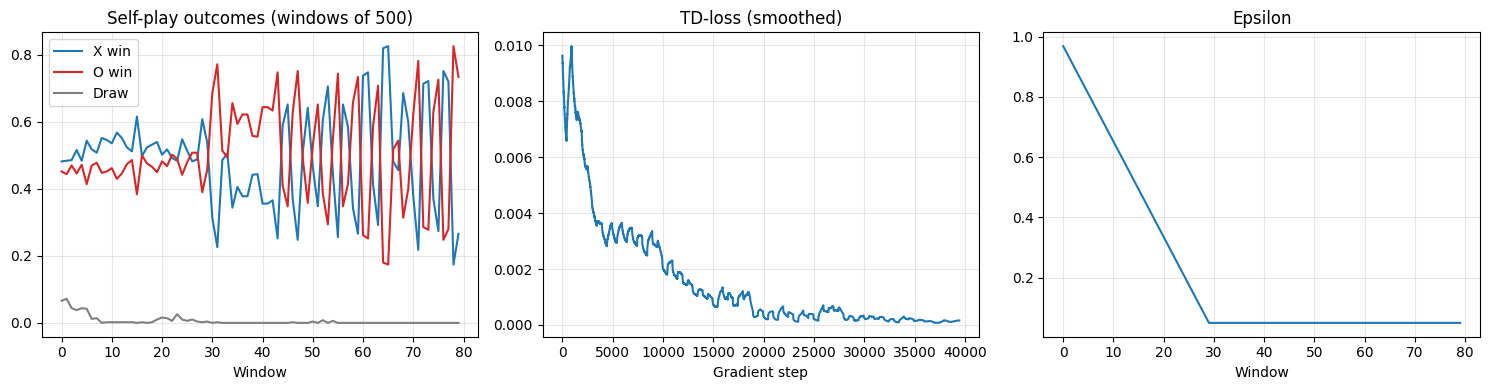

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(hist["win_x"], label="X win", color="tab:blue")
axes[0].plot(hist["win_o"], label="O win", color="tab:red")
axes[0].plot(hist["draw"],  label="Draw",  color="gray")
axes[0].set_title("Self-play outcomes (windows of 500)")
axes[0].set_xlabel("Window"); axes[0].legend(); axes[0].grid(alpha=.3)

if hist["loss"]:
    l = np.array(hist["loss"])
    k = min(500, len(l))
    smooth = np.convolve(l, np.ones(k)/k, mode="valid") if k > 1 else l
    axes[1].plot(smooth)
axes[1].set_title("TD-loss (smoothed)")
axes[1].set_xlabel("Gradient step"); axes[1].grid(alpha=.3)

axes[2].plot(hist["eps"])
axes[2].set_title("Epsilon")
axes[2].set_xlabel("Window"); axes[2].grid(alpha=.3)

plt.tight_layout()
plt.show()

In [30]:
from ipywidgets import Button, HBox, VBox, Label, Layout

def play_vs_agent_gui(net, human_player=1):
    env = TicTacToe5()
    if human_player == 2:
        state = env.get_state()
        action = select_action(net, state, env.legal_moves(), epsilon=0.0)
        env.step(action)

    symbols = {0: "·", 1: "X", 2: "O"}
    buttons = {}
    status = Label(value="Ваш ход", layout=Layout(margin='10px 0px'))

    def update_buttons():
        for r in range(BOARD_SIZE):
            for c in range(BOARD_SIZE):
                v = int(env.board[r, c])
                b = buttons[(r, c)]
                b.description = symbols[v]
                b.disabled = bool(env.done or (v != EMPTY))

    # Создаём кнопки
    for r in range(BOARD_SIZE):
        for c in range(BOARD_SIZE):
            b = Button(description="·", layout=Layout(width='45px', height='45px', margin='1px'))
            b.on_click(lambda btn, r=r, c=c: on_click(r, c))
            buttons[(r, c)] = b

    # Собираем доску в сетку (список строк)
    board_rows = []
    for r in range(BOARD_SIZE):
        row = HBox([buttons[(r, c)] for c in range(BOARD_SIZE)])
        board_rows.append(row)
    board_ui = VBox(board_rows, layout=Layout(margin='10px 0px'))

    # Обработчик клика
    def on_click(r, c):
        if env.done:
            return
        if env.current_player != human_player:
            return
        if int(env.board[r, c]) != EMPTY:
            return

        action = r * BOARD_SIZE + c
        _, _, done, info = env.step(action)

        # Ход агента
        if not done:
            state = env.get_state()
            a = select_action(net, state, env.legal_moves(), epsilon=0.0)
            _, _, done, info = env.step(a)

        # Обновляем текст статуса
        if done:
            if info["winner"] == 0:
                status.value = "Ничья!"
            elif info["winner"] == human_player:
                status.value = "Вы победили! 🎉"
            else:
                status.value = "Агент победил 🤖"
        else:
            status.value = "Ваш ход"

        update_buttons()

    # Сброс игры
    def reset_game(b=None):
        env.reset()
        status.value = "Ваш ход"
        if human_player == 2:
            state = env.get_state()
            a = select_action(net, state, env.legal_moves(), epsilon=0.0)
            env.step(a)
        update_buttons()

    reset_btn = Button(description="Новая игра", button_style='success', layout=Layout(margin='10px 0px'))
    reset_btn.on_click(reset_game)

    # Инициализируем вид
    update_buttons()

    # Выводим всё разом
    display(VBox([status, board_ui, reset_btn]))




In [31]:
play_vs_agent_gui(net, human_player=2)

In [26]:
@torch.no_grad()
def play_vs_random(net, n_games=200, agent_as=1):
    wins = losses = draws = 0
    for _ in range(n_games):
        env = TicTacToe5()
        state = env.get_state()
        while not env.done:
            if env.current_player == agent_as:
                action = select_action(net, state, env.legal_moves(), epsilon=0.0)
            else:
                action = int(random.choice(np.flatnonzero(env.legal_moves())))
            state, _, done, info = env.step(action)
        if   info["winner"] == 0:         draws  += 1
        elif info["winner"] == agent_as:  wins   += 1
        else:                             losses += 1
    return wins / n_games, losses / n_games, draws / n_games


for as_p in (1, 2):
    w, l, d = play_vs_random(net, n_games=300, agent_as=as_p)
    print(f"Agent as {'X' if as_p==1 else 'O'}: "
          f"win={w:.2%}  loss={l:.2%}  draw={d:.2%}")

Agent as X: win=85.00%  loss=14.00%  draw=1.00%
Agent as O: win=81.33%  loss=17.67%  draw=1.00%
